# 21 - Custom Workflows: Your Own Reusable Interpretation Recipe

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/21_custom_workflows.ipynb)

**Part B - Petrophys Curriculum**

`pp.interpret` looks at a well and chooses its methods for you. Often you need the
opposite: a recipe that *you* choose (these endpoints, this porosity route, this Rw,
these cutoffs), applied the same way to every well, checked before it runs, and saved
so a colleague can run it too. That is a **custom workflow**: a `Workflow` built
from the library's tested calculation steps and from your own functions.

This lesson builds a clastic recipe for 30/6-5 and a carbonate recipe for the COSTA
Kharaib-2 wells, adds steps of your own, wraps the automatic `pp.interpret` inside a
recipe, saves and reloads the recipes, and runs one across the field.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Build a `Workflow` from `petrophys.workflow.steps` and read its `describe()` table.
- Check a workflow against a well with `check()`, and understand strict and
  non-strict runs.
- Read a run's trace, window summary, formation table, plot and exports.
- Write your own step with `@workflow_step`, and put `pp.interpret` inside a
  recipe with `steps.interpret()`.
- Save, reload and share a workflow, and change a parameter for one run with `params=`.
- Run one workflow over many wells with `run_many` and compare them in a table and a figure.

### Prerequisites

Lesson 10 (the prebuilt dynamic workflow and its trace) and the Part A calculation
lessons (clay volume, porosity, Rw, saturation, net pay). Lesson 18 introduces the
COSTA field used in sections 7 and 8.

## Why this matters

A field study is only comparable if every well is interpreted with the same recipe,
and a recipe is only reviewable if it is written down. With `pp.interpret` the methods
can differ from well to well, because it adapts to the data. A custom workflow fixes
the methods and parameters, refuses to run when an input is missing instead of quietly
doing something else, records every decision, and travels as a small JSON file. It is
the difference between "I ran the interpretation" and "here is exactly what was run".

In [2]:
import json
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import petrophys as pp
from petrophys.visualization import create_bar_comparison
from petrophys.workflow import Workflow, WorkflowValidationError, steps, workflow_step

## 1. A clastic recipe for 30/6-5

We start from the flagship North Sea well and its bundled formation tops. Whenever
this well's curves are standardized (for a plot, or inside `pp.interpret`), Petrophys
prints a `UserWarning` for `SWC` and one for `SOC`: the core saturation curves are
stored in percent although the header labels them `frac`, so they are divided by 100.
It is a genuine note about this file, not about the lesson, and it would repeat in
every run below, so we hide **only that message** up front.

In [3]:
# Hide only the SWC/SOC percent note explained above; other warnings still show.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
well

Well(30/6-5, curves=20, samples=22176)

Each step comes from `petrophys.workflow.steps` and wraps a tested library
calculation; the steps choose no methods on their own. Our choices, all visible in the
recipe:

| Step | Choice | Why |
|---|---|---|
| `temperature()` | Linear profile from the header BHT | Rw is corrected to formation temperature |
| `clay_volume` | Gamma ray, 20 and 110 API endpoints | Clean sand and shale read off the GR log |
| `porosity` | Neutron-density, sandstone matrix | The standard clastic route |
| `formation_water` | Rw 0.07 ohm.m measured at 230 degF | The documented Rw for this well |
| `saturation` | Archie, a = 1, m = 2, n = 2 | A simple, transparent starting point |
| `permeability` | Timur with Swirr 0.15 | An explicit Swirr instead of a log estimate |
| `net_pay` | VCL < 0.35, PHIE > 0.10, SW < 0.60 | Project cutoffs |

Like `pp.interpret`, `steps.net_pay` also leaves non-reservoir samples out of net
reservoir and net pay: coal and evaporite codes of a lithology code log (30/6-5
has one, `LITHOLOGY_GEOLINK`), halite recognised from its logs, and `BAD_HOLE` samples where the well
carries that flag. `exclude_non_reservoir=False` applies the cutoffs alone.

In [4]:
clastic = Workflow("30/6-5 clastic quick look", [
    steps.temperature(),
    steps.clay_volume(method="gr", gr_clean=20, gr_shale=110),
    steps.porosity(method="neutron_density", matrix="sandstone"),
    steps.formation_water(rw=0.07, rw_temp_f=230),
    steps.saturation(model="archie", a=1, m=2, n=2),
    steps.permeability(method="timur", swirr=0.15),
    steps.net_pay(vcl_cutoff=0.35, phie_cutoff=0.10, sw_cutoff=0.60),
])
clastic.describe()

,Step,Kind,Requires,Produces,Parameters
1,temperature,temperature,-,TEMP,defaults
2,clay_volume,clay_volume,GR,VCL,"method='gr', gr_clean=20, gr_shale=110"
3,porosity,porosity,"NPHI, RHOB, VCL","PHID, PHIN, PHIT, PHIE","method='neutron_density', matrix='sandstone'"
4,formation_water,formation_water,-,RW,"rw=0.07, rw_temp_f=230"
5,saturation,saturation,"PHIE, RDEP or RT, RW","SW, SXO","model='archie', a=1, m=2, n=2"
6,permeability,permeability,PHIE,PERM,"method='timur', swirr=0.15"
7,net_pay,net_pay,"VCL, PHIE, SW","NET_ROCK, NET_RES, NET_PAY","vcl_cutoff=0.35, phie_cutoff=0.1, sw_cutoff=0.6"


`describe()` is the recipe at a glance: what each step needs, what it adds, and the
parameters you set (everything else is a documented default). Parameters are validated
when a step is created, so mistakes surface immediately, with the closest valid option:

In [5]:
for attempt in (lambda: steps.porosity(method="densty"),
                lambda: steps.net_pay(vcl=0.35),
                lambda: steps.formation_water(rw=0.07)):
    try:
        attempt()
    except (TypeError, ValueError) as error:
        print(f"{type(error).__name__}: {error}\n")

ValueError: Invalid steps.porosity() parameters:
  - method='densty' is not valid; use one of: density, neutron_density, neutron, sonic (did you mean 'density'?)

TypeError: steps.net_pay() got unexpected parameter(s) 'vcl' (did you mean 'vcl_cutoff'?). Parameters: vcl_cutoff, phie_cutoff, sw_cutoff, lithology, vcl_curve, phie_curve, sw_curve, exclude_non_reservoir.

ValueError: Invalid steps.formation_water() parameters:
  - rw_temp_f is required with rw: the temperature (degF) at which rw was measured, e.g. rw=0.07, rw_temp_f=230



## 2. Check before you run

`check()` walks the steps in order and reports, for every input, where it will come
from: the well itself or an earlier step.

In [6]:
clastic.check(well)

,Step,Requires,Met,Source,Note
0,temperature,(nothing),True,,
1,clay_volume,GR,True,well (GR),
2,porosity,NPHI,True,well (NPHI),
3,porosity,RHOB,True,well (RHOB),
4,porosity,VCL,True,step clay_volume,
5,formation_water,(nothing),True,,
6,saturation,PHIE,True,step porosity,
7,saturation,RDEP or RT,True,well (RDEP),
8,saturation,RW,True,step formation_water,
9,permeability,PHIE,True,step porosity,


Break the recipe on purpose by dropping the clay-volume step. `check` shows the
missing input *and* its consequences further down - here the rows whose input is not met:

In [7]:
draft = clastic.copy("draft without clay volume").remove("clay_volume")
draft.check(well).query("not Met")[["Step", "Requires", "Note"]]

,Step,Requires,Note
3,porosity,VCL,"needs VCL (clay volume), which is not on this ..."
5,saturation,PHIE,"needs PHIE (effective porosity), which step 'p..."
8,permeability,PHIE,"needs PHIE (effective porosity), which step 'p..."
9,net_pay,VCL,"needs VCL (clay volume), which is not on this ..."
10,net_pay,PHIE,"needs PHIE (effective porosity), which step 'p..."
11,net_pay,SW,"needs SW (water saturation), which step 'satur..."


A normal (strict) run stops before calculating anything and lists every problem at once:

In [8]:
try:
    draft.run(well)
except WorkflowValidationError as error:
    print(error)

Workflow 'draft without clay volume' cannot run on well '30/6-5':
  - porosity: needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'porosity'
  - saturation: needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
  - permeability: needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
  - net_pay: needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'net_pay'
  - net_pay: needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
  - net_pay: needs SW (water saturation), which step 'saturation' would produce but cannot run
Run wf.check(well) for the full table, or pass strict=False to skip these steps and run the rest.


With `strict=False` the run goes ahead, skips what cannot run, and says why. It is
useful for exploring, but always read `steps_skipped`: a skipped step is missing work,
not a zero.

In [9]:
partial = draft.run(well, strict=False)
partial.status, partial.steps_skipped

('partial',
 {'porosity': "Needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'porosity'",
  'saturation': "Needs PHIE (effective porosity), which step 'porosity' would produce but cannot run",
  'permeability': "Needs PHIE (effective porosity), which step 'porosity' would produce but cannot run",
  'net_pay': "Needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'net_pay'; needs PHIE (effective porosity), which step 'porosity' would produce but cannot run; needs SW (water saturation), which step 'saturation' would produce but cannot run"})

Order is part of the recipe. A step can only use curves from the well or from
*earlier* steps, so adding a step whose output an earlier step needed is refused at once:

In [10]:
try:
    Workflow("wrong order", [steps.saturation()]).add(
        steps.formation_water(rw=0.07, rw_temp_f=230))
except WorkflowValidationError as error:
    print(error)

Steps run in order, so these inputs would never be available:
  - 'saturation' needs RW, which only the later step 'formation_water' produces; move 'formation_water' before 'saturation' (wf.insert(step, before='saturation'))


## 3. Run it and read the result

`run()` works on a copy of the well: `run.well` is the interpreted copy and `well`
is untouched. The trace records each step's method, inputs, outputs and decisions,
including values the step picked itself.

In [11]:
run = clastic.run(well)
run.print_trace()

WORKFLOW TRACE: 30/6-5 clastic quick look on 30/6-5
Status: complete | Run: 7 | Skipped: 0 | Warnings: 0
[OK  ] temperature  (linear_gradient_from_BHT)
       Outputs: TEMP
       -> Anchored to BHT 258.8 degF at 11667 ft
       -> Gradient 1.635 degF/100 ft (29.8 degC/km); TEMP 77.5-258.8 degF
[OK  ] clay_volume  (gr_linear)
       Inputs:  GR
       Outputs: VCL
       -> GR clean = 20.0 API (given), GR shale = 110.0 API (given); linear transform
[OK  ] porosity  (neutron_density)
       Inputs:  RHOB, NPHI, VCL
       Outputs: PHID, PHIN, PHIT, PHIE
       -> PHID = (2.65 - RHOB) / (2.65 - 1)
       -> PHIN = NPHI + 0.02, limited to 0-0.6
       -> PHIT = adaptive neutron-density combination (PHID in crossover, hc_type='oil')
       -> PHIE = PHIT - VCL * 0.15
[OK  ] formation_water  (given_rw_arps)
       Inputs:  TEMP
       Outputs: RW
       -> Corrected along the TEMP curve
       -> Rw 0.07 ohm.m at 230 degF (given), corrected with Arps' equation
       -> RW 0.0624-0.1967 ohm

On 30/6-5 a whole-well total would include shallow overburden that happens to pass
the cutoffs, so we summarize the Brent Group window (2841-2958 m) with
`summary(top=..., bottom=...)`, next to `pp.interpret` with the same Rw. The net
thicknesses differ because the recipes differ: `pp.interpret` picks its own clay
endpoints, a matrix per lithology and a saturation model per sample, and flags bad
hole. That is exactly why writing the recipe down matters.

In [12]:
auto = pp.interpret(well, rw=0.07, rw_meas_temp_f=230)
pd.DataFrame({"custom recipe": run.summary(top=2841, bottom=2958)["net_thickness"],
              "pp.interpret": auto.summary(top=2841, bottom=2958)["net_thickness"]})

,custom recipe,pp.interpret
depth_unit,m,m
net_rock,57.15,76.5
net_res,55.78,65.99
net_pay,20.73,26.06


`formation_summary` gives the same per-formation table as for `pp.interpret`; the two
Brent Group formations:

In [13]:
table = run.formation_summary(rank="formation").query("Formation in ['Ness Fm.', 'Etive Fm.']")
table[["Formation", "Gross (m)", "Net Pay (m)", "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]].round(3)

,Formation,Gross (m),Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg Perm (mD)
6,Ness Fm.,24.079,0.305,0.013,0.196,0.578,295.152
7,Etive Fm.,92.964,20.422,0.220,0.214,0.271,420.240


The interpreted copy plots like any other well:

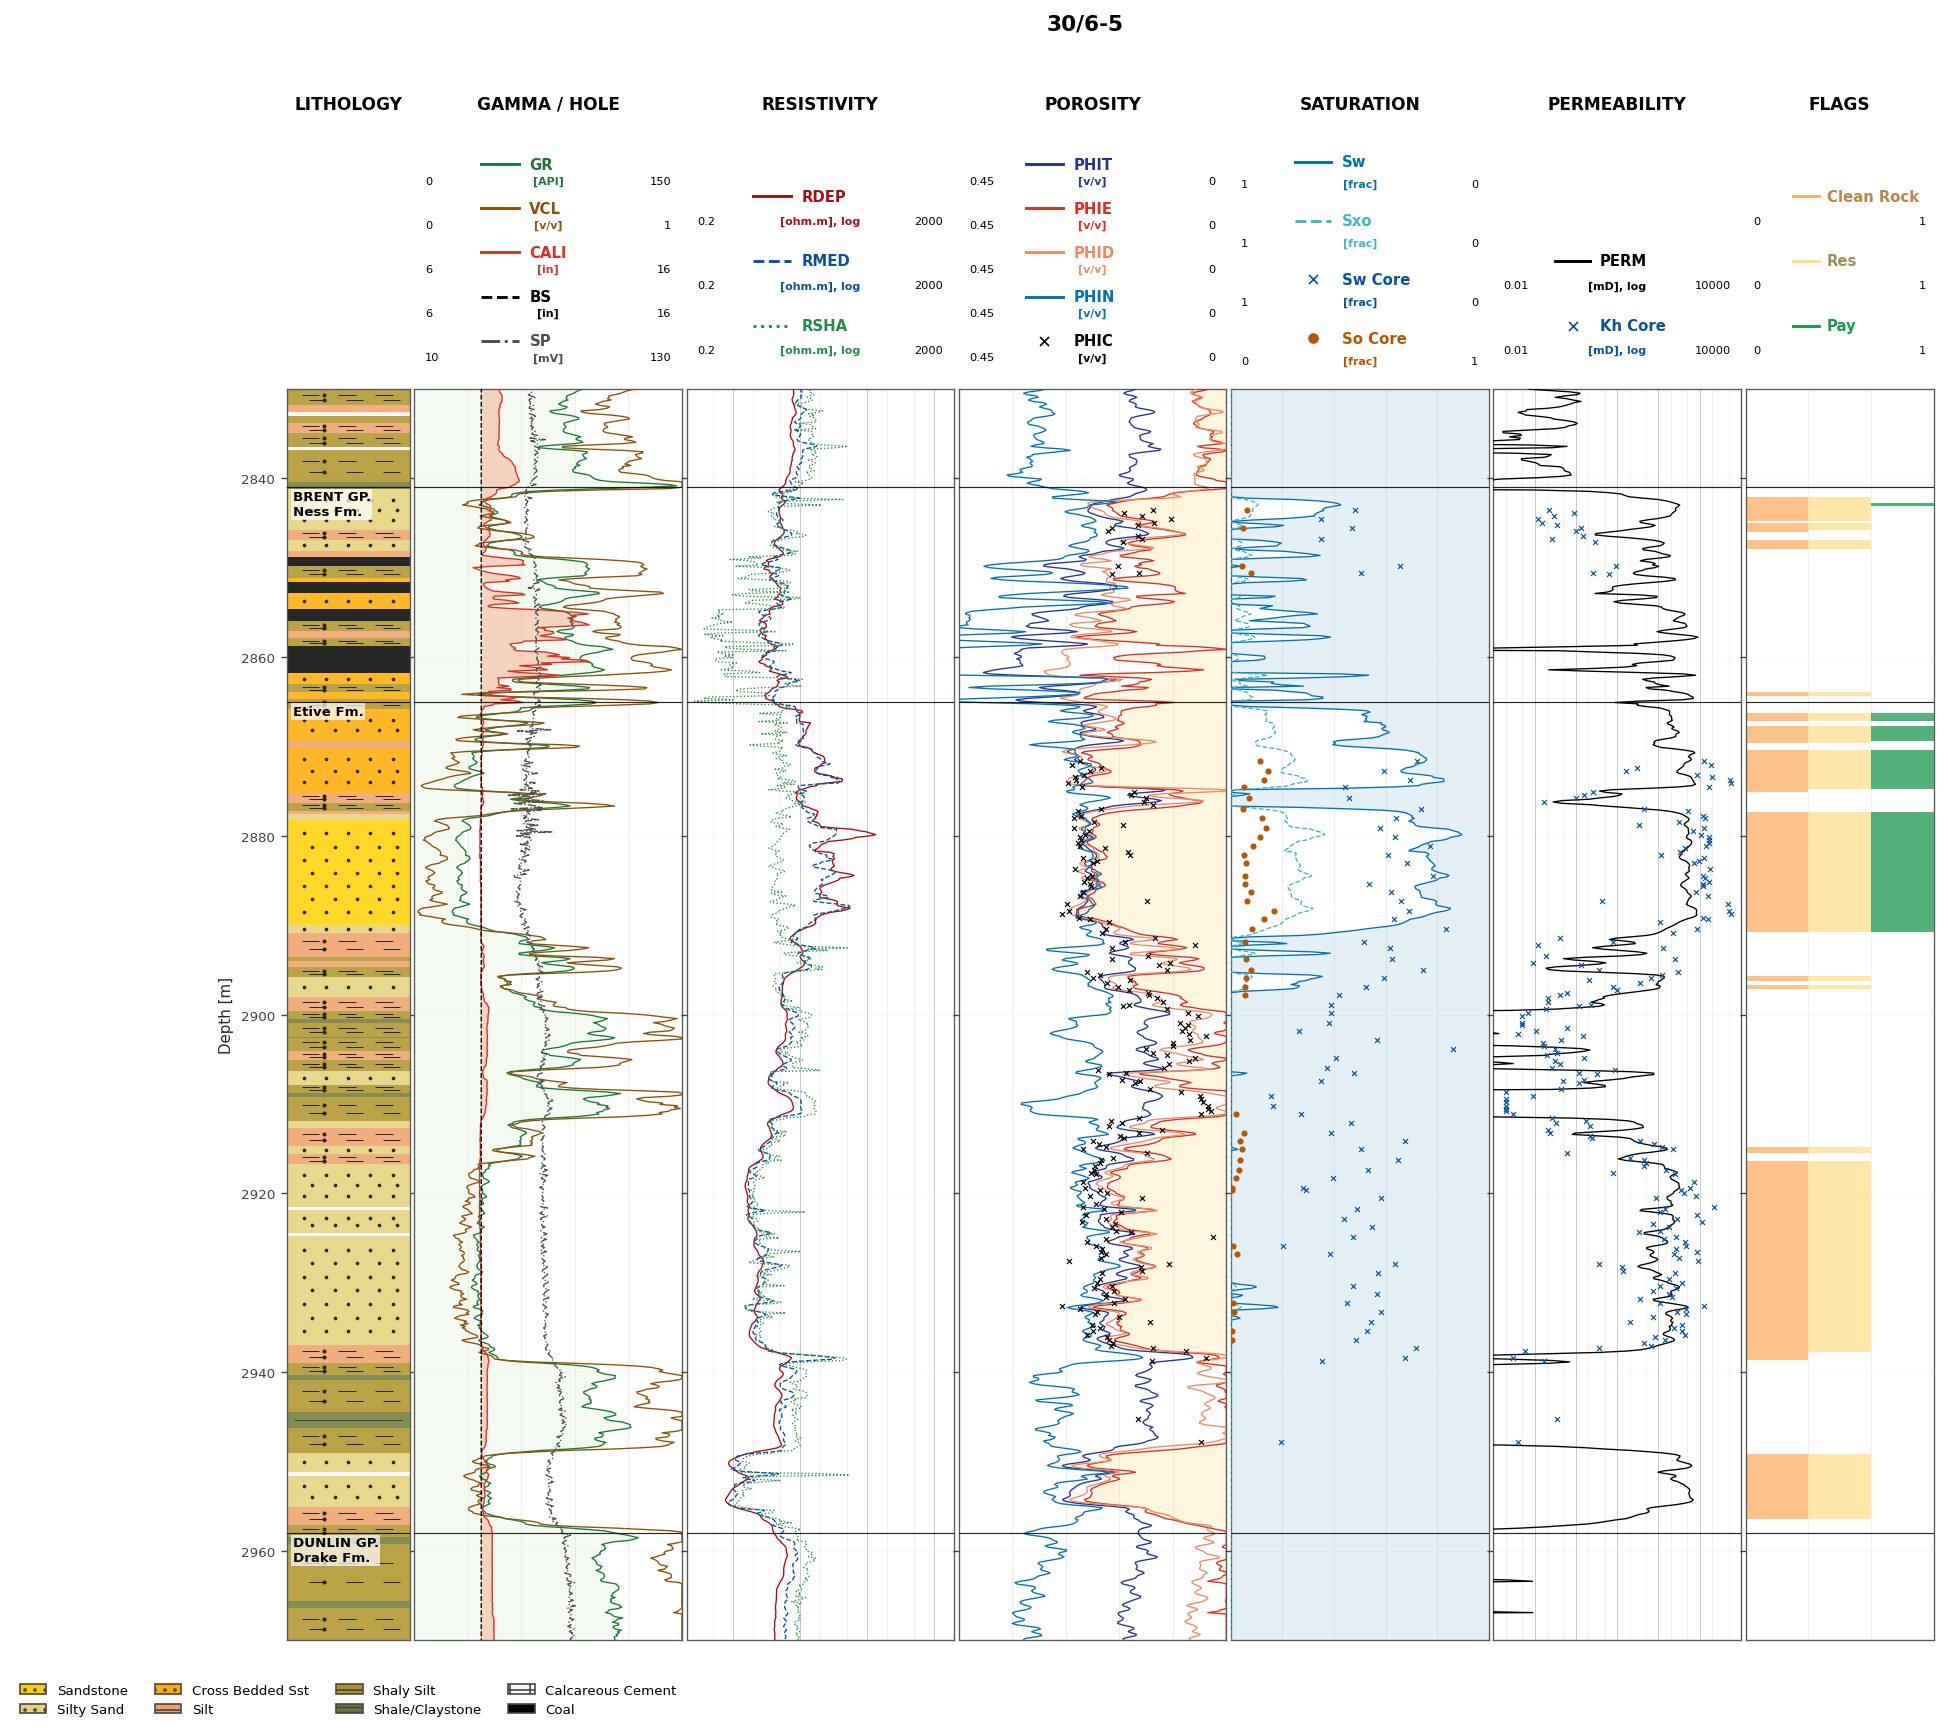

In [14]:
pp.plot(run.well, top=2830, bottom=2970,
        tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "POROSITY", "SATURATION", "PERMEABILITY", "FLAGS"]).show()

## 4. Your own step: an apparent-Rw check

Any function can become a step. It takes the well first and its parameters as
keywords, and returns its curves as a `{name: array}` dict with one value per depth
sample. `requires` and `produces` declare the inputs and the outputs with their
units, so `check()` and the trace treat it like a built-in step.

Our step computes the apparent water resistivity, Rwa = Rt x PHIE^m / a. In clean,
water-bearing sand Rwa should scatter around the true Rw, so it is a classic check on
the Rw we assumed.

In [15]:
@workflow_step(requires=["RDEP", "PHIE"], produces={"RWA": "ohm.m"})
def apparent_rw(well, a=1.0, m=2.0):
    """Apparent water resistivity, Rwa = RT * PHIE^m / a."""
    phie = np.clip(well.get("PHIE").data, 0.0, None)
    return {"RWA": well.get("RDEP").data * phie**m / a}

checked = clastic.copy("30/6-5 quick look + Rwa").add(apparent_rw())
run = checked.run(well)
run.to_dataframe().tail(1)

,Step,Kind,Status,Method,Input Curves,Output Curves,Parameters,Decisions,Warnings,Message
7,apparent_rw,__main__:apparent_rw,OK,__main__.apparent_rw,"RDEP, PHIE",RWA,"a=1.0, m=2.0",,,


The trace's last row is the custom step, with its inputs and outputs like any built-in
step. In this recipe the lower Etive (about 2895-2955 m) is water-bearing. Compare Rwa
in its clean, porous samples (VCL < 0.3, PHIE > 0.10) with the Rw curve the workflow used:

In [16]:
run.well.to_dataframe(curves=["RWA", "RW", "VCL", "PHIE"]).query(
    "2895 <= DEPTH <= 2955 and VCL < 0.3 and PHIE > 0.10")[["RWA", "RW"]].describe().round(3)

,RWA,RW
count,178.000,178.000
mean,0.055,0.071
std,0.013,0.000
min,0.025,0.071
25%,0.048,0.071
50%,0.054,0.071
75%,0.061,0.072
max,0.107,0.072


Over these clean water-leg samples Rwa has a median of 0.054 ohm.m against a median Rw
of 0.071 ohm.m. If Rwa sits clearly *below* the assumed Rw in a zone you believe is
wet, as here, either Rw is too high or porosity (or m) is off; if it sits *above*, the
zone may hold hydrocarbon. The step does not decide for you, but it puts the evidence
next to the recipe, and it reruns on every well the recipe touches. Exercise 1 follows
this up.

## 5. Put `pp.interpret` inside a recipe

`steps.interpret(**settings)` runs the complete prebuilt workflow as one step. The
settings are the usual `pp.interpret` settings, validated when the step is created.
Your own steps can follow it (or precede it), and `steps.formation_summary()` computes
the per-formation table as part of the run.

In [17]:
extended = Workflow("pp.interpret + Rwa check", [
    steps.interpret(rw=0.07, rw_meas_temp_f=230),
    apparent_rw(),
    steps.formation_summary(rank="formation"),
])
extended_run = extended.run(well)
extended_run

Step,Status,Method,Output Curves,Message
interpret,OK,petrophys.interpret,"TEMP, BAD_HOLE, VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_ND, VCLND, RMF, PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC, VQUAR, VCALC, VDOLO, VANHY, PHIE_CC, RW, INVASION_RATIO, SW, SXO, RESFLAG, PERM, PERM_CC, SWIRR_APP, RQI, PHI_Z, FZI, BVW, MHI, NET_ROCK, NET_RES, NET_PAY, SEALFLAG, CROSSOVER_FLAG, PRIME_OIL_TARGET, NET_EXCLUSION",
apparent_rw,OK,__main__.apparent_rw,RWA,
formation_summary,OK,formation_table,,


The step's trace (`run.step("interpret")`) condenses the automatic routing to one line
per sub-step (the first eight below), and the full `DynamicWorkflowResult` stays available in
`run.artifacts["interpret"]`; the formation table is in
`run.artifacts["formation_summary"]`.

In [18]:
extended_run.step("interpret").decisions[:8]

['normalization: curve_alias_and_unit_standardization',
 'input_context: validated_geology_selection',
 'temperature: linear_gradient_from_BHT',
 'bad_hole: caliper_drho_flags',
 'vclay: linear',
 'rcl: lithology_shale_median_rt',
 'rmf: las_metadata_assumed_reference_temperature',
 'porosity: component_based']

In [19]:
table = extended_run.artifacts["formation_summary"].query("Formation in ['Ness Fm.', 'Etive Fm.']")
table[["Formation", "Gross (m)", "Net Pay (m)", "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]].round(3)

,Formation,Gross (m),Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg Perm (mD)
6,Ness Fm.,24.079,2.59,0.108,0.21,0.541,423.277
7,Etive Fm.,92.964,23.47,0.252,0.22,0.250,589.314


## 6. Save, reload, share and vary

A workflow saves as a small JSON file: the step types, names and the parameters you
set. Loading re-creates every step through its factory, so everything is validated
again. We write into a temporary folder; the saved file is shown below the cell.

In [20]:
folder = Path(tempfile.mkdtemp())
path = clastic.save(folder / "30_6-5_clastic.json")
json.loads(path.read_text())

{'schema': 'petrophys.workflow',
 'schema_version': 1,
 'petrophys_version': '3.0.0',
 'name': '30/6-5 clastic quick look',
 'description': '',
 'steps': [{'name': 'temperature', 'kind': 'temperature', 'params': {}},
  {'name': 'clay_volume',
   'kind': 'clay_volume',
   'params': {'method': 'gr', 'gr_clean': 20, 'gr_shale': 110}},
  {'name': 'porosity',
   'kind': 'porosity',
   'params': {'method': 'neutron_density', 'matrix': 'sandstone'}},
  {'name': 'formation_water',
   'kind': 'formation_water',
   'params': {'rw': 0.07, 'rw_temp_f': 230}},
  {'name': 'saturation',
   'kind': 'saturation',
   'params': {'model': 'archie', 'a': 1, 'm': 2, 'n': 2}},
  {'name': 'permeability',
   'kind': 'permeability',
   'params': {'method': 'timur', 'swirr': 0.15}},
  {'name': 'net_pay',
   'kind': 'net_pay',
   'params': {'vcl_cutoff': 0.35, 'phie_cutoff': 0.1, 'sw_cutoff': 0.6}}]}

In [21]:
Workflow.load(path) == clastic

True

Custom steps are saved by import path (`module:function`). `apparent_rw` lives in this
notebook (`__main__`), so saving a recipe that uses it warns that the file only loads
where that function is defined. To share such a recipe, put the step in a module.

In [22]:
checked.save(folder / "30_6-5_with_rwa.json");

[temporary directory]\ipykernel_24348\205042784.py:1: UserWarning: Custom step 'apparent_rw' is defined in __main__ (a script or notebook); the saved workflow can only be loaded where that function is defined. Move it into an importable module to share the workflow.
  checked.save(folder / "30_6-5_with_rwa.json");


Results travel with their recipe: `to_las` writes the workflow into the LAS `~Params`
section (one `PP_STEPnn` entry per step, the full JSON in `~Other`), and `to_json`
writes the complete trace. The `PP_` lines of the LAS file:

In [23]:
las = run.to_las(folder / "30_6-5_quicklook.las")
[line for line in las.read_text().splitlines() if line.startswith("PP_")]

['PP_VERSION                       .                        3.0.0 : petrophys version',
 'PP_WORKFLOW                      .      30/6-5 quick look + Rwa : Custom workflow',
 'PP_STATUS                        .                     complete : Workflow status',
 'PP_STEP01                        .                  temperature : steps.temperature() [run]',
 "PP_STEP02                        .                  clay_volume : steps.clay_volume(method='gr', gr_clean=20, gr_shale=110) [run]",
 "PP_STEP03                        .                     porosity : steps.porosity(method='neutron_density', matrix='sandstone') [run]",
 'PP_STEP04                        .              formation_water : steps.formation_water(rw=0.07, rw_temp_f=230) [run]',
 "PP_STEP05                        .                   saturation : steps.saturation(model='archie', a=1, m=2, n=2) [run]",
 "PP_STEP06                        .                 permeability : steps.permeability(method='timur', swirr=0.15) [run]",
 'PP

In [24]:
trace = json.loads(run.to_json())
trace["schema"], trace["status"], len(trace["steps"])

('custom_workflow_trace', 'complete', 8)

`params=` changes a step for one run without editing the workflow, which makes a
sensitivity check one line: the Brent Group net pay (m) for three saturation exponents.

In [25]:
{n: clastic.run(well, params={"saturation": {"n": n}}).summary(top=2841, bottom=2958)["net_thickness"]["net_pay"]
 for n in (1.8, 2.0, 2.2)}

{1.8: 21.18, 2.0: 20.73, 2.2: 20.12}

The recipe itself is unchanged:

In [26]:
clastic["saturation"]

steps.saturation(model='archie', a=1, m=2, n=2)

## 7. A carbonate recipe for the COSTA Kharaib-2 wells

Each COSTA LAS file covers only the Kharaib-2 reservoir interval, in feet. The
carbonate recipe differs from the clastic one in four deliberate ways:

- **Limestone matrix** for porosity.
- **Field-wide GR endpoints** (10 and 80 API). The Kharaib-2 is mostly clean
  carbonate: per-well P5/P95 endpoints would call each well's dirtiest rock "shale"
  and inflate clay volume.
- **Rw from each well's header.** `rw="header"` reads `RW` and the temperature it was
  measured at (`RWT`) from every file, so one recipe honours each well's water.
- **The COSTA project cutoffs** used in lesson 18: VCL 0.30, PHIE 0.10, SW 0.60.

The files also carry the vendor's interpretation (`PHIE_CC`, `SW_INPUT`). A small
custom step compares our result with it, so the QC is part of the recipe.

In [27]:
@workflow_step(requires=["PHIE", "SW", "PHIE_CC", "SW_INPUT"], produces={"DPHIE": "v/v", "DSW": "v/v"})
def vendor_difference(well):
    """Our PHIE and SW minus the vendor's PHIE_CC and SW_INPUT."""
    return {"DPHIE": well.get("PHIE").data - well.get("PHIE_CC").data,
            "DSW": well.get("SW").data - well.get("SW_INPUT").data}

carbonate = Workflow("Kharaib-2 carbonate screen", [
    steps.temperature(),
    steps.clay_volume(method="gr", gr_clean=10, gr_shale=80),
    steps.porosity(method="neutron_density", matrix="limestone"),
    steps.formation_water(rw="header"),
    steps.saturation(model="archie", a=1, m=2, n=2),
    steps.net_pay(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60, lithology="carbonate"),
    vendor_difference(),
])
carbonate.describe()

,Step,Kind,Requires,Produces,Parameters
1,temperature,temperature,-,TEMP,defaults
2,clay_volume,clay_volume,GR,VCL,"method='gr', gr_clean=10, gr_shale=80"
3,porosity,porosity,"NPHI, RHOB, VCL","PHID, PHIN, PHIT, PHIE","method='neutron_density', matrix='limestone'"
4,formation_water,formation_water,header RW and RWT,RW,rw='header'
5,saturation,saturation,"PHIE, RDEP or RT, RW","SW, SXO","model='archie', a=1, m=2, n=2"
6,net_pay,net_pay,"VCL, PHIE, SW","NET_ROCK, NET_RES, NET_PAY","vcl_cutoff=0.3, phie_cutoff=0.1, sw_cutoff=0.6..."
7,vendor_difference,custom: vendor_difference,"PHIE, SW, PHIE_CC, SW_INPUT","DPHIE, DSW",defaults


In [28]:
hw3_run = carbonate.run(pp.read(pp.sample("HW-3"), formations=pp.sample("formations_costa")))
hw3_run.to_dataframe()[["Step", "Method", "Output Curves", "Decisions"]]

,Step,Method,Output Curves,Decisions
0,temperature,linear_gradient_from_BHT,TEMP,Anchored to BHT 251.0 degF at 8299 ft | Gradie...
1,clay_volume,gr_linear,VCL,"GR clean = 10.0 API (given), GR shale = 80.0 A..."
2,porosity,neutron_density,"PHID, PHIN, PHIT, PHIE",PHID = (2.71 - RHOB) / (2.71 - 1) | PHIN = NPH...
3,formation_water,header_rw_arps,RW,Corrected along the TEMP curve | Rw 0.0682 ohm...
4,saturation,archie,"SW, SXO",SXO: fifth_root_quicklook (RSHA/RXO/RESS and R...
5,net_pay,cutoffs,"NET_ROCK, NET_RES, NET_PAY",NET_ROCK: VCL < 0.3 -> 431 samples (215.5 ft) ...
6,vendor_difference,__main__.vendor_difference,"DPHIE, DSW",


The log plot puts the recipe's `PHIE` next to the vendor's `PHIE_CC` in the porosity
track and `SW` next to `SW_INPUT` in the saturation track:

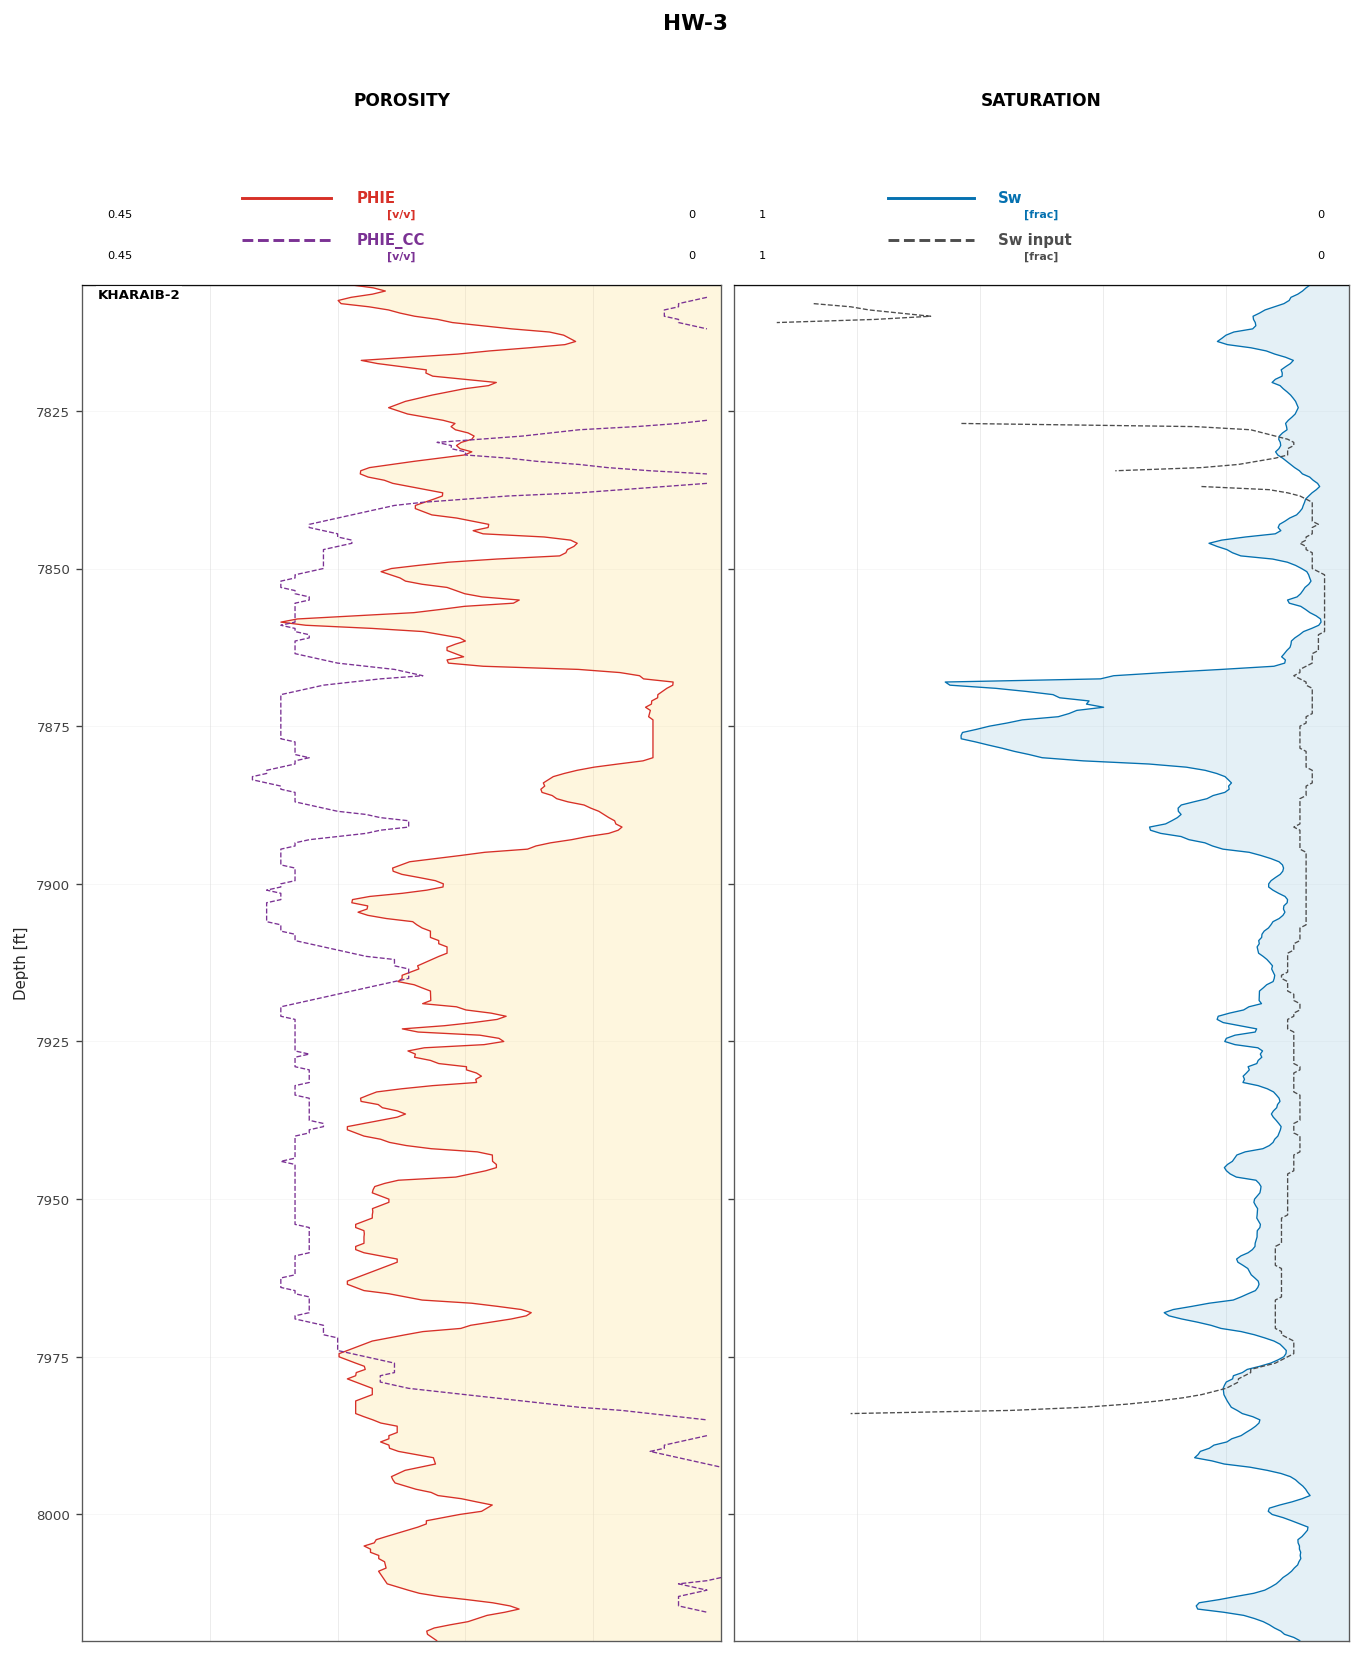

In [29]:
pp.plot(hw3_run.well, curves=["PHIE", "PHIE_CC", "SW", "SW_INPUT"]).show()

The custom step's curves give the differences over the well; `statistics` summarizes them:

In [30]:
hw3_run.statistics(["DPHIE", "DSW"]).round(3)

,unit,samples,mean,p10,median,p90
DPHIE,v/v,351,-0.054,-0.188,-0.071,0.169
DSW,v/v,321,0.062,0.001,0.049,0.220


## 8. Run the field with `run_many`

`run_many` takes a list of wells or files, or a folder, attaches the same formation
tops to every well, and keeps going when a well fails: each failure is recorded with
its reason.

In [31]:
wells = [pp.sample(name) for name in pp.list_samples("costa")]
batch = carbonate.run_many(wells, formations=pp.sample("formations_costa"))
batch.errors

{'HW-31': "WorkflowValidationError: Workflow 'Kharaib-2 carbonate screen' cannot run on well 'HW-31':\n  - vendor_difference: needs SW_INPUT, which has no valid samples on this well\nRun wf.check(well) for the full table, or pass strict=False to skip these steps and run the rest."}

HW-31's file has a `SW_INPUT` curve with no valid values, so the comparison step
cannot run there and the strict run refuses the whole well. With `strict=False` the
well runs every other step and skips only the comparison:

In [32]:
batch = carbonate.run_many(wells, formations=pp.sample("formations_costa"), strict=False)
field = batch.summary_table()
field[["Well", "Status", "Skipped Steps", "Gross", "Net Pay", "Pay/Gross", "Avg PHIE", "Avg Sw"]].round(3)

,Well,Status,Skipped Steps,Gross,Net Pay,Pay/Gross,Avg PHIE,Avg Sw
0,HW-10,complete,,190.5,11.0,0.058,0.243,0.515
1,HW-24,complete,,216.5,147.0,0.679,0.240,0.270
2,HW-25,complete,,206.5,151.5,0.734,0.254,0.096
3,HW-26,complete,,172.5,34.5,0.200,0.147,0.435
4,HW-27,complete,,204.5,0.0,0.000,NaN,NaN
5,HW-28,complete,,203.5,4.5,0.022,0.137,0.535
6,HW-29,complete,,222.5,188.0,0.845,0.281,0.102
7,HW-3,complete,,215.5,194.5,0.903,0.207,0.133
8,HW-30,complete,,240.5,209.5,0.871,0.303,0.137
9,HW-31,partial,vendor_difference,210.5,0.0,0.000,NaN,NaN


`summary_table()` gives one row per well: status, the steps run and skipped, and net
pay with pay-averaged properties over the logged interval (or a `top`/`bottom` window;
`by_formation=True` gives one row per formation). Ranked, the net pay column becomes
the field chart:

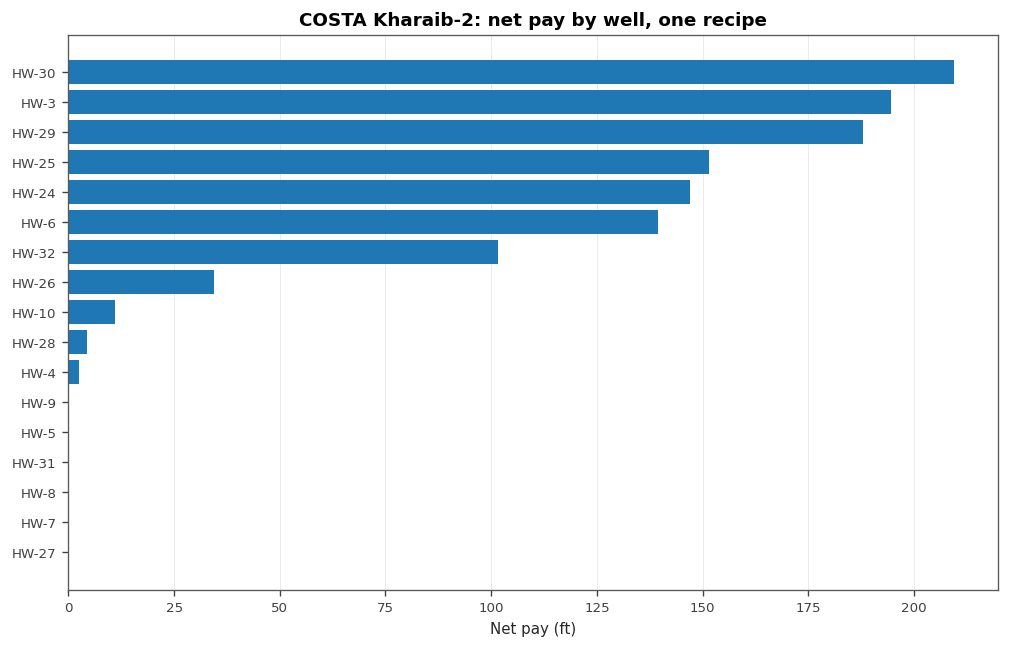

In [33]:
create_bar_comparison(field["Well"], field["Net Pay"], horizontal=True, sort_by=0, descending=True,
                      xlabel="Net pay (ft)", title="COSTA Kharaib-2: net pay by well, one recipe");

To check the recipe against the vendor across the field, compare each well's mean `SW`
with the mean of the vendor's `SW_INPUT` (HW-31's `SW_INPUT` has no valid values, so its
vendor mean is missing):

In [34]:
pd.DataFrame({name: result.well.to_dataframe(curves=["SW", "SW_INPUT"], include_depth=False).mean()
              for name, result in batch.results.items()}).T.round(3)

,SW,SW_INPUT
HW-10,0.911,0.669
HW-24,0.472,0.267
HW-25,0.309,0.105
HW-26,0.848,0.608
HW-27,0.993,0.802
HW-28,0.980,0.805
HW-29,0.243,0.097
HW-3,0.167,0.120
HW-30,0.249,0.168
HW-31,1.000,NaN


In every well with vendor values the recipe reads wetter than the vendor: its mean SW
lies above the mean `SW_INPUT` by 0.05 (HW-3) to 0.39 (HW-7). An offset shared by all
the wells points to a recipe-wide choice (Rw, m, n or the porosity route) rather than to
one well, and is worth resolving before trusting the ranking: the recipe makes that
choice explicit and easy to change.

The same recipe answers "what if" questions across the field: here the total net pay
for three Sw cutoffs, each a one-line `params` change.

In [35]:
pd.Series({cutoff: carbonate.run_many(wells, strict=False, params={"net_pay": {"sw_cutoff": cutoff}}).summary_table()["Net Pay"].sum()
           for cutoff in (0.5, 0.6, 0.7)}, name="field net pay (ft)")

0.5    1128.5
0.6    1184.0
0.7    1242.5
Name: field net pay (ft), dtype: float64

## Pitfalls & parameter choices

- **A custom workflow does not choose methods.** A step you did not add does not run.
  If a well uses vendor mnemonics or percent units, start the recipe with
  `steps.standardize()`.
- **Order is part of the recipe.** Steps see only the well and earlier steps' curves;
  `add` refuses a step whose output an earlier step needed.
- **Default endpoints are per well.** `clay_volume` without `gr_clean`/`gr_shale`
  takes P5/P95 of each well's GR, which assumes every well contains both clean rock and
  shale. In a clean carbonate it does not, so set field-wide endpoints. Explicit
  endpoints are used exactly as given.
- **Rw needs its temperature.** `formation_water(rw=...)` requires `rw_temp_f`;
  `rw="header"` needs `RW` and `RWT` in each file, and `check()` shows which wells lack them.
- **`strict=False` hides problems unless you read them.** Look at `steps_skipped` and
  the `Skipped Steps` column: a skipped step is missing work, not a zero.
- **Steps can replace input curves.** A step writing a curve the well already has
  replaces it on the run's copy, and the trace says "Replaced input curve".
- **Custom steps are saved by import path.** A step defined in a notebook reloads only
  in that session; put shared steps in a module.
- **Whole-well totals on 30/6-5 include overburden.** Summarize reservoir windows or
  formations, as in section 3.

## Recap

- `Workflow` and `petrophys.workflow.steps` turn an interpretation recipe into an
  object you can describe, check, run, save and share.
- `check()` and strict runs catch missing inputs before any calculation;
  `strict=False` skips and explains.
- A run keeps the interpreted well, a full trace, window and formation summaries,
  artifacts, and LAS and JSON exports that carry the recipe.
- `@workflow_step` makes any function a step; `steps.interpret()` puts the
  automatic `pp.interpret` inside your own recipe.
- `run_many` applies one recipe to a field, records failures per well, and
  `summary_table()` compares the wells.

## Try it yourself

> **Exercise 1.** In section 4, the water-leg Rwa does not sit exactly on the assumed
> Rw. Re-run the clastic recipe with `params={"formation_water": {"rw": ...,
> "rw_temp_f": 230}}` until the water-leg Rwa and Rw agree. How does the Brent Group net pay
> change, and what other explanation (porosity, m) could you test the same way?
>
> **Exercise 2.** Replace Archie in the carbonate recipe with the Indonesia model:
> `carbonate.replace("saturation", steps.saturation(model="indonesia"))`. Run `check()`
> first: what does the new model need that Archie did not?
>
> **Exercise 3.** Write a step that returns the hydrocarbon pore thickness per sample,
> `PHIE * (1 - SW) * NET_PAY * step`, add it to the carbonate recipe, and rank the
> COSTA wells by its sum. Does the ranking differ from the net-pay ranking?

## What's next

This completes Part B. The case studies apply these tools to whole projects:
**cs1_full_formation_evaluation_30_6-5.ipynb** takes 30/6-5 from raw logs to a
reviewed interpretation, and **cs3_field_screening_costa_17wells.ipynb** screens the
whole COSTA field. For a compact reference of every built-in step, see the Custom
workflows page of the user guide and `petrophys.workflow.steps` in the API reference.